# UMAP Cell cycle

This notebook simulates the cell cycle for different conditions (in particular the different stiffness and erl processing of the experiments) and then computes the umap for these different points. The objective is to be able to visualise a complex and multidimensional process with a reduced number of dimensions. In particular, this allows a qualitative comparison of the cycle for different inputs.

The points correspond to the different proteins of the system on different consecutive sampling times. The simulation times of the stochastic simulation algorithm as well as the umap can take some time. It is therefore possible to save the results of the simulation and then the results of the umap to avoid simulating everything at each attempt.

## I) Stochastic simulations of the cell cycle

In this section the simulation of the cell cycle model is performed for different stiffness and treatment inputs. The stochastic simulation is performed by the PySB package based on the stochastic simulation algorithm (SSA).

First, we import the different packages, as well as the model and its kinetic parameters

In [75]:
import os
import sys
sys.path.insert(0, os.getcwd() + "/cellular_cycle") #add a pathway to the model #not sure about how to use folder dependency, to change
sys.path.insert(0, os.getcwd() + "/fit") #add a pathway to the fit functions #not sure about how to use folder dependency, to change

##Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count
from Austin_proliferation_model_concentration_5 import model
model_concentration=model
from Austin_proliferation_model_population_5 import model
model_population=model

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


import pandas as pd
import numpy as np
import umap
from scipy.signal import find_peaks
import scipy as sp
import matplotlib.pyplot as plt

Load the model parameters set the time and run simulations for each conditions. Then the simulations can be saved

In [76]:
init_dt = 0.01
t = np.linspace(0, 5000, 500001);

conditions = ['0.2 kPa DMSO', '0.2 kPa ERL', '4 kPa DMSO', '4 kPa ERL', '55 kPa DMSO', '55 kPa ERL']

omega = 200
new_param = pd.read_csv('parameters.csv') 
del new_param['Stress']

for key in new_param.keys():
    if model_population.parameters[key].value != new_param[key][0]:
        model_population.parameters[key].value = new_param[key]
    if model_concentration.parameters[key].value != new_param[key][0]:
        model_concentration.parameters[key].value = new_param[key]




In [ ]:
all_prot = {}
#conditions = ['4 kPa DMSO']

for condition in conditions:
    print(condition)
    if 'DMSO' in condition:  
        print('DMSO')
        if '0.2 kPa' in condition :
            
            #print('0.6 kPa')
            model_population.parameters['ERK'].value = 1.0 * omega ###
            model_population.parameters['FAK'].value = 0.4 * omega
            model_population.parameters['AKT'].value = 0.6 * omega ###
        elif '4 kPa' in condition :
            model_population.parameters['ERK'].value = 1.0 * omega
            model_population.parameters['FAK'].value = 0.6 * omega
            model_population.parameters['AKT'].value = 1.0 * omega
        else : #55 kPa
            #print('55 kPa')
            model_population.parameters['ERK'].value = 1 * omega
            model_population.parameters['FAK'].value = 1 * omega
            model_population.parameters['AKT'].value = 1 * omega
    else : #ERL treated
        print('ERL')
        if '0.2 kPa' in condition :
            #print('0.6 kPa')
            model_population.parameters['ERK'].value = 0.2 * omega
            model_population.parameters['FAK'].value = 0.4 * omega
            model_population.parameters['AKT'].value = 0.3 * omega
        elif '4 kPa' in condition :
            #print('4 kPa')
            model_population.parameters['ERK'].value = 0.2 * omega
            model_population.parameters['FAK'].value = 0.6 * omega
            model_population.parameters['AKT'].value = 0.6 * omega
        else : #55 kPa
            #print('55 kPa')
            model_population.parameters['ERK'].value = 0.2 * omega
            model_population.parameters['FAK'].value = 1.0 * omega
            model_population.parameters['AKT'].value = 0.6 * omega
        
    sim = BngSimulator(model_population, tspan=t, verbose=False); #stochastic simulator
    simres = sim.run(method='ssa', verbose=False); #running the simulation
    yout = simres.observables;
    yout_tmp = pd.DataFrame(yout)/200;
    yout_tmp = yout_tmp[['obsSkp2', 'obsp21', 'obsp21p', 'obscdh1act', 'obsMyc', 'obsCycD', 'obsCycDp21', 'obspRb', 'obspRbp', 'obsE2F', 'obspRbE2F', 'obsCycE', 'obsCycEp21', 'obsCycA', 'obsCycAp21', 'obsCycB', 'obsCycBp21', 'obsCdc20']];
    yout_tmp = yout_tmp.set_axis(["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21", "cycB", "cycB-p21", "cdc20"], axis=1, inplace=False);
    yout_tmp.columns;
    all_prot[condition] = yout_tmp;

In [ ]:
#Saving simulations for all the conditions

for condition in conditions:
    all_prot[condition].to_csv('all_prot_' + condition.replace(' ', '_') + '_pysb.csv', index=False)

In [80]:
#loading the simulations for all the conditions
all_prot = {}

for condition in conditions:
    all_prot[condition] = pd.read_csv('all_prot_' + condition.replace(' ', '_') + '_pysb.csv')


Comparing simulations and saved files (to be removed)

500001

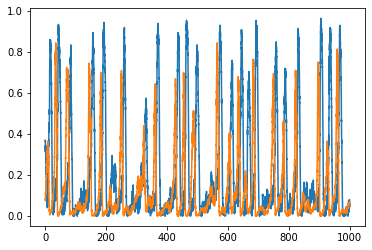

In [78]:
condition = '0.2 kPa ERL'
#condition = '55 kPa ERL'
T=100000

plt.plot(t[0:T], all_prot[condition]["cdc20"][0:T])
plt.plot(t[0:T], all_prot[condition]["cycE"][0:T])

len(all_prot[condition]["cdc20"])

500001

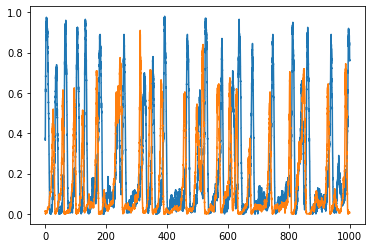

In [79]:
prot_tmp = pd.read_csv('erl_4-9_1_1.txt', sep=",", header=None, usecols = range(0,18)) #4 kPa
#prot_tmp = pd.read_csv('dmso_4-9_2_1.txt', sep=",", header=None, usecols = range(0,18))
prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
    "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
    "cycB", "cycB-p21", "cdc20"]
    
### UMAP Parameters
plt.plot(t[0:T], prot_tmp["cdc20"][0:T])
plt.plot(t[0:T], prot_tmp["cycE"][0:T])

len(prot_tmp["cdc20"])


## II) UMAP

In this part the umap of the previous simulation is calculated in order to visualise the cell cycle with fewer dimensions while keeping its dynamic structure.

### Setting UMAP parameters

First we choose the parameters for the umap. There are two types of parameters: the system sampling parameters and the umap parameters. The sampling parameters correspond to the sampling period of the simulation (dt in hours), the size of the window corresponding to a point (window in hours) and finally the time elapsed between two points in the umap (time_step in hours). The parameters of the umap correspond to the number of neighbours and the minimum distance.

In [42]:
#Important params to set the window size and step time distance
#26072
init_dt = 0.01                #initial dt from the raw model output

#sampling parameters
dt = 0.02             #dt for umap window
window = 2            #window size in hours
time_step = 0.04      #time step between windows
#umap parameters
neighbs = 200         #number of neighbors
min_d = 0.05          #minimal distance



time_tmp = pd.DataFrame(t)
time_tmp.columns = ["time"]
time_tmp2 = time_tmp.iloc[::int(dt//init_dt)].reset_index().drop(columns=['index'])

Merge the simulations for the different conditions in a single dataframe

In [43]:
#create window and total protein arrays
win_len = int(window/dt)
all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
all_time_tmp = np.empty((0,win_len))
all_time_at_tmp = np.empty((0,1))
range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))

conditions = ['0.2 kPa DMSO', '0.2 kPa ERL', '4 kPa DMSO', '4 kPa ERL', '55 kPa DMSO', '55 kPa ERL'] #all the conditions are used to generate the umap reducer

for f in conditions:
    prot_tmp = all_prot[f]
    prot_tmp2 = prot_tmp.iloc[::int(dt//init_dt),:].reset_index().drop(columns=['index'])
    
    prot_re_tmp = np.empty((len(range_ind),win_len*18))
    time_re_tmp = np.empty((len(range_ind),win_len))
    time_at_tmp = np.empty((len(range_ind),1))

    ii=0
    for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
        tmp = prot_tmp2.iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp=tmp.to_numpy()
        tmp=np.reshape(np.transpose(tmp),win_len*18)
        tmp_at = time_tmp2['time'].iloc[n]
        
        prot_re_tmp[ii,:] = np.array([tmp])
        time_re_tmp[ii,:] = np.array([tmp_t])
        time_at_tmp[ii,:] = np.array([[tmp_at]])
        ii+=1
        
    all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
    all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
    all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)


We then fit the UMAP to the dataset

In [44]:
reducer = umap.UMAP(
        n_neighbors=neighbs,
        min_dist=min_d,
        n_components=2,
        metric='euclidean',
        random_state=2,
        low_memory=True        
        ).fit(all_prot_tmp)

#embedding_all_prot = reducer.transform(all_prot_tmp)

And transform the dataset with the umap space

In [54]:
#create window and total protein arrays
win_len = int(window/dt)
range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))

condition_plot = ['0.2 kPa ERL', '4 kPa ERL', '55 kPa ERL'] #we transform the ERL treated datasets
#condition_plot = ['0.2 kPa ERL']
#condition_plot = ['4 kPa ERL', '55 kPa ERL']


for condition_tmp in condition_plot:
    prot_tmp = all_prot[condition_tmp]
    prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
    "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
    "cycB", "cycB-p21", "cdc20"]
    prot_tmp2 = prot_tmp.iloc[::int(dt//init_dt),:].reset_index().drop(columns=['index'])
    
    prot_re_tmp = np.empty((len(range_ind),win_len*18))
    time_re_tmp = np.empty((len(range_ind),win_len))
    time_at_tmp = np.empty((len(range_ind),1))

    ii=0
    for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
        tmp = prot_tmp2.iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp=tmp.to_numpy()
        tmp=np.reshape(np.transpose(tmp),win_len*18)
        tmp_at = time_tmp2['time'].iloc[n]
        
        prot_re_tmp[ii,:] = np.array([tmp])
        time_re_tmp[ii,:] = np.array([tmp_t])
        time_at_tmp[ii,:] = np.array([[tmp_at]])
        ii+=1
    
    embedding_all_prot = reducer.transform(prot_re_tmp)
    condition_tmp_save = condition_tmp.replace(" ", "_")
    name = 'embedding_erl_'+condition_tmp_save+'.csv'

    np.savetxt('embedding_'+ condition_tmp_save +'.csv', embedding_all_prot, delimiter=',', fmt='%f')
    np.savetxt('all_time_'+ condition_tmp_save +'.csv', time_re_tmp, delimiter=',', fmt='%f')
    np.savetxt('all_time_at_'+ condition_tmp_save +'.csv', time_at_tmp, delimiter=',', fmt='%f')
    np.savetxt('all_prot_'+ condition_tmp_save +'.csv', prot_re_tmp, delimiter=',', fmt='%f')

Save then load the umap transformed dataset.

In [55]:
time_re_tmp = pd.read_csv('/home/jeremie/umap_window/all_time_0.2_kPa_ERL.csv',header=None)
time_at_tmp = pd.read_csv('/home/jeremie/umap_window/all_time_at_0.2_kPa_ERL.csv',header=None)
#times

all_time_stoch = time_re_tmp
all_time_at_stoch = pd.DataFrame(time_at_tmp)


#UMAP stochastic
embedding_prot_erl_7_7_1_1 = pd.read_csv('/home/jeremie/umap_window/embedding_0.2_kPa_ERL.csv',header=None)
embedding_prot_erl_7_7_2_1 = pd.read_csv('/home/jeremie/umap_window/embedding_4_kPa_ERL.csv',header=None)
embedding_prot_erl_7_7_3_1 = pd.read_csv('/home/jeremie/umap_window/embedding_55_kPa_ERL.csv',header=None)

#prot stochastic
all_prot_erl_7_7_1_1 = pd.read_csv('/home/jeremie/umap_window/all_prot_0.2_kPa_ERL.csv',header=None)
all_prot_erl_7_7_2_1 = pd.read_csv('/home/jeremie/umap_window/all_prot_4_kPa_ERL.csv',header=None)
all_prot_erl_7_7_3_1 = pd.read_csv('/home/jeremie/umap_window/all_prot_55_kPa_ERL.csv',header=None)


This function ensures that the data has alternating cyclin E - cdc20 peaks. You will have to change find peaks based on the size of the window (peaks_E for example: 11*window_size+(window_size/2) and peaks_cdc: 17*window_size+(window_size/2)

In [57]:
window_size = len(all_prot_erl_7_7_1_1.columns)/18
cyce=int((window_size*11+window_size/2)-1)
cdc20=int((window_size*17+window_size/2)-1)


In [58]:
def restructProt(protDF, embedDF, timeDF, cyce, cdc20):
    peaks_E, _ = find_peaks(protDF[cyce], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF[cdc20], prominence = 40/200, distance = 10)
    
    #print(peaks_E)
    #print(peaks_cdc)
    
    mit_win = pd.DataFrame()
    time_win = pd.DataFrame()
    umap_win = pd.DataFrame()
    
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)] 
        
        #print(tmp_g1_s)
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            #print('t')
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp_umap = embedDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp_time = timeDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp = np.concatenate(tmp, axis=0)
            tmp_time.insert(1, 'G1', tmp)
            
            mit_win = pd.concat([mit_win,tmp_prot],ignore_index=True)
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            umap_win = pd.concat([umap_win, tmp_umap], ignore_index=True)
            
    return mit_win, time_win, umap_win

In [63]:

mit_win_erl_1_1, time_win_erl_1_1, umap_win_erl_1_1 = restructProt(all_prot_erl_7_7_1_1, embedding_prot_erl_7_7_1_1, all_time_at_stoch, cyce, cdc20)
mit_win_erl_2_1, time_win_erl_2_1, umap_win_erl_2_1 = restructProt(all_prot_erl_7_7_2_1, embedding_prot_erl_7_7_2_1, all_time_at_stoch, cyce, cdc20)
mit_win_erl_3_1, time_win_erl_3_1, umap_win_erl_3_1 = restructProt(all_prot_erl_7_7_3_1, embedding_prot_erl_7_7_3_1, all_time_at_stoch, cyce, cdc20)


## III) Plot UMAP for different conditions

In [68]:
xmin, xmax = -9, 18
ymin, ymax = -5, 18
bins = 900
sigma = 3 * np.ones(2)


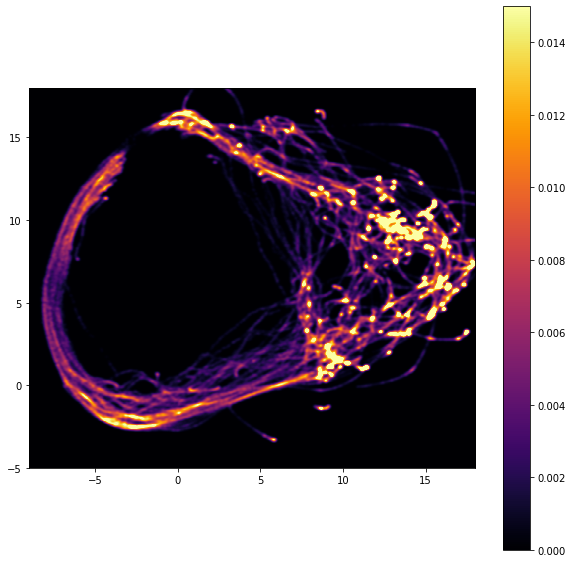

In [69]:
#x = np.array(embedding_prot_erl_7_7_1_1[0])
#y = np.array(embedding_prot_erl_7_7_1_1[1])
x = np.array(umap_win_erl_1_1[0])
y = np.array(umap_win_erl_1_1[1])

#H, xedges, yedges = np.histogram2d(x, y, bins=500, range= [[-5,16], [-6,18]], density=True)
H, xedges, yedges = np.histogram2d(x, y, bins=bins, range= [[xmin, xmax], [ymin, ymax]], density=True)
# Apply gaussian filter
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


fig = plt.figure()
ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
fig.set_size_inches(10, 10)
plt.imshow(np.rot90(H2), extent=[xmin, xmax, ymin, ymax], cmap='inferno')

plt.clim(0, 0.015)
plt.colorbar()


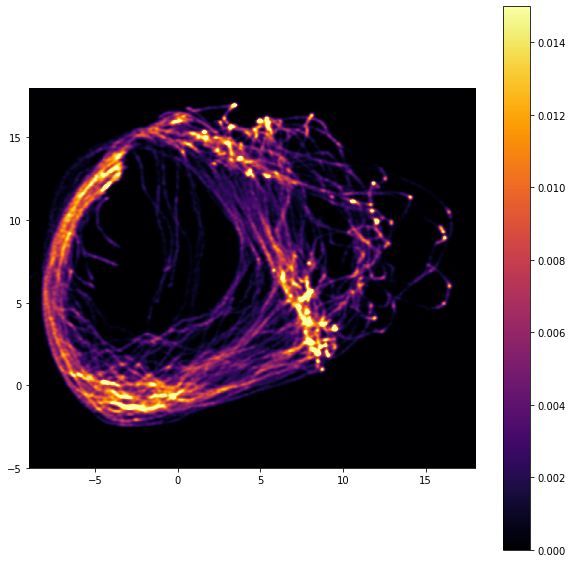

In [70]:
#x = np.array(embedding_prot_erl_7_7_2_1[0])
#y = np.array(embedding_prot_erl_7_7_2_1[1])
x = np.array(umap_win_erl_2_1[0])
y = np.array(umap_win_erl_2_1[1])

H, xedges, yedges = np.histogram2d(x, y, bins=bins, range= [[xmin, xmax], [ymin, ymax]], density=True)
# Apply gaussian filter
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


fig = plt.figure()
ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
fig.set_size_inches(10, 10)
plt.imshow(np.rot90(H2), extent=[xmin, xmax, ymin, ymax], cmap='inferno')

plt.clim(0, 0.015)
plt.colorbar()


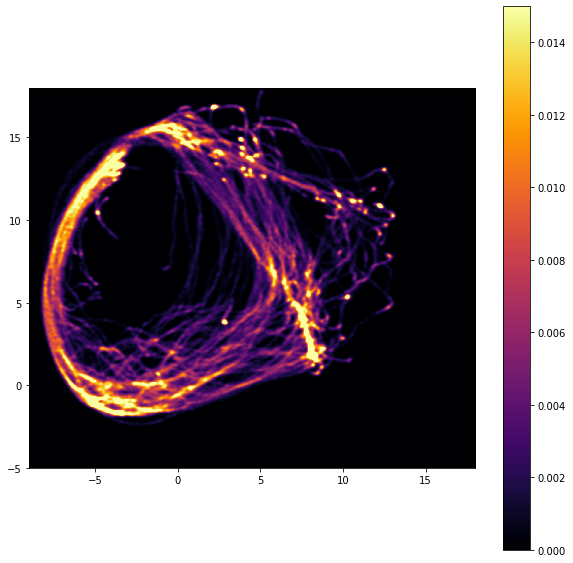

In [71]:
#x = np.array(embedding_prot_erl_7_7_3_1[0])
#y = np.array(embedding_prot_erl_7_7_3_1[1])
x = np.array(umap_win_erl_3_1[0])
y = np.array(umap_win_erl_3_1[1])

H, xedges, yedges = np.histogram2d(x, y, bins=bins, range= [[xmin, xmax], [ymin, ymax]], density=True)
# Apply gaussian filter
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0


fig = plt.figure()
ax = fig.gca()
#ax.set_xlim(xmin, xmax)
#ax.set_ylim(ymin, ymax)
fig.set_size_inches(10, 10)
plt.imshow(np.rot90(H2), extent=[xmin, xmax, ymin, ymax], cmap='inferno')

plt.clim(0, 0.015)
plt.colorbar()
